# Meme Match — live facial-expression + hand-gesture → meme matching
Every meme in `memes.csv` and every webcam frame is described the same way, then the closest meme wins.

**Face.** MediaPipe Face Landmarker gives 52 blendshape scores and 478 3-D landmarks. Instead of comparing the raw blendshapes, we condense them into **22 expression channels** for the eyes, brows and mouth (left/right pairs averaged, plus signed channels for one-sided things like a wink, side-eye or smirk). Blendshapes that barely move (`eyeWide`, `mouthFrown`, …) are backed up by measurements taken straight from the landmarks: eyelid gap, brow height, mouth opening, mouth width and mouth-corner lift.

**Hands.** MediaPipe Hand Landmarker gives 21 landmarks per hand. We keep where each hand is relative to the face (in face-widths) and how straight each finger is.

**Matching.** Each channel is scaled by how much it varies across the memes, so no single feature dominates. Your face is measured relative to *your own* relaxed face (captured in the first second of the webcam loop), which removes personal offsets such as naturally narrow eyes or looking down at the screen.

Files: `memes.csv` (cleaned list) · `memes/` (images) · `collect_memes.py` (how they were downloaded/cropped) · `face_landmarker.task`, `hand_landmarker.task` (models; the hand model comes from `https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task`).
Dependencies are already installed in the Python 3.11 kernel. If you ever need to reinstall, run `pip install mediapipe opencv-python pandas matplotlib "numpy<2"` — keep the `numpy<2` pin: numpy 2 breaks the TensorFlow in this Python, which MediaPipe loads on import.

In [1]:
import time, cv2, numpy as np, pandas as pd, mediapipe as mp, matplotlib.pyplot as plt
from mediapipe.tasks.python import vision, BaseOptions

def make_face(mode):
    return vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path='face_landmarker.task'),
        running_mode=mode, output_face_blendshapes=True, num_faces=1))

def make_hands(mode, conf=0.5):
    return vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
        base_options=BaseOptions(model_asset_path='hand_landmarker.task'), running_mode=mode,
        num_hands=2, min_hand_detection_confidence=conf, min_hand_presence_confidence=conf))

def to_mp(bgr):
    return mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))

## 1. Features: expression channels and hands
`face_channels` turns one Face Landmarker result into the 22 channels; `find_hands` turns one Hand Landmarker result into a list of hands. Both are used unchanged for the memes and for the webcam.

In [2]:
def face_channels(res, shape):
    """Face Landmarker result -> ({channel: value}, face centre in px, face width in px), or None if no face.
    Blendshape 'Left'/'Right' are the subject's own left/right."""
    if not res.face_blendshapes: return None
    b = {c.category_name: c.score for c in res.face_blendshapes[0]}
    h, w = shape[:2]
    P = np.array([(p.x * w, p.y * h, p.z * w) for p in res.face_landmarks[0]])     # 3-D landmarks in pixels
    dist = lambda i, j: np.linalg.norm(P[i] - P[j])
    mid  = lambda *i: P[list(i)].mean(0)
    avg  = lambda n: (b[n + 'Left'] + b[n + 'Right']) / 2
    dif  = lambda n: b[n + 'Left'] - b[n + 'Right']
    size = dist(33, 263)                                    # outer eye corners = face scale
    across = (P[263] - P[33]) / size                        # unit vector along the eye line
    up = P[10] - P[152]; up -= (up @ across) * across; up /= np.linalg.norm(up)    # chin -> forehead
    ch = dict(
        # eyes
        eye_open    = (dist(159, 145) / dist(33, 133) + dist(386, 374) / dist(362, 263)) / 2,   # eyelid gap / eye width
        eye_wide    = avg('eyeWide'),
        eye_squint  = avg('eyeSquint'),
        wink        = dif('eyeBlink'),                                                          # signed
        gaze_side   = (b['eyeLookOutLeft'] + b['eyeLookInRight'] - b['eyeLookInLeft'] - b['eyeLookOutRight']) / 2,  # signed
        gaze_up     = avg('eyeLookUp') - avg('eyeLookDown'),
        # brows
        brow_raise  = (b['browInnerUp'] + avg('browOuterUp')) / 2,
        brow_furrow = avg('browDown'),
        brow_height = ((P[105] - mid(33, 133)) @ up + (P[334] - mid(362, 263)) @ up) / 2 / size,
        brow_cock   = dif('browOuterUp') - dif('browDown'),                                     # signed: one brow up
        # mouth
        smile       = avg('mouthSmile'),
        corner_lift = (mid(61, 291) - mid(0, 17)) @ up / size,      # mouth corners above (+) / below (-) the lip centre
        jaw_open    = b['jawOpen'],
        mouth_open  = dist(13, 14) / size,
        mouth_width = dist(61, 291) / size,
        pucker      = max(b['mouthPucker'], b['mouthFunnel']),
        lips_tight  = (avg('mouthPress') + b['mouthRollLower'] + b['mouthRollUpper']) / 3,
        upper_lip   = avg('mouthUpperUp'),                          # top teeth showing / sneer
        lower_lip   = avg('mouthLowerDown'),                        # bottom teeth showing
        stretch     = avg('mouthStretch'),                          # grimace
        pout        = b['mouthShrugLower'],
        smirk       = dif('mouthSmile') + b['mouthLeft'] - b['mouthRight'],                     # signed
    )
    return ch, mid(33, 263)[:2], size

FINGERS = [(1, 2, 3, 4), (5, 6, 7, 8), (9, 10, 11, 12), (13, 14, 15, 16), (17, 18, 19, 20)]   # thumb .. pinky
REACH = 6          # ignore hands further than this many face-widths from the face

def find_hands(res, shape, centre, size):
    """Hand Landmarker result -> list of hands, each a dict:
    pos = palm centre relative to the face centre, in face-widths (x right, y down)
    ext = how straight the index..pinky fingers are, 0 (curled) .. 1 (straight)
    px  = the 21 landmarks in pixels (for drawing)"""
    h, w = shape[:2]; hands = []
    for lm, world in zip(res.hand_landmarks, res.hand_world_landmarks):
        px = np.array([(p.x * w, p.y * h) for p in lm])
        X  = np.array([(p.x, p.y, p.z) for p in world])                                # metric 3-D
        straight = [np.linalg.norm(X[f[3]] - X[f[0]]) / sum(np.linalg.norm(X[f[k + 1]] - X[f[k]]) for k in range(3))
                    for f in FINGERS[1:]]                                               # 1 = straight, ~0.7 = curled
        pos = (px[[0, 5, 9, 13, 17]].mean(0) - centre) / size
        if np.linalg.norm(pos) < REACH:
            hands.append(dict(pos=pos, ext=np.clip((np.array(straight) - 0.7) / 0.25, 0, 1), px=px))
    return hands

def describe(hand):
    """Short readable label for a hand, e.g. 'pointing, by face'."""
    up = hand['ext'] > 0.5
    shape = ('fist' if not up.any() else 'open hand' if up.all() else 'pointing' if up[0] and not up[1:].any()
             else 'two fingers' if up[:2].all() and not up[2:].any() else 'hand')
    d = np.linalg.norm(hand['pos'])
    return f"{shape}, {'by face' if d < 1.6 else 'below face' if hand['pos'][1] > 1.6 else 'out to the side'}"

## 2. Describe every meme and build the matcher

In [3]:
memes = pd.read_csv('memes.csv')
memes['img'] = [cv2.imread(f) for f in memes.file]

still_face, still_hands = make_face(vision.RunningMode.IMAGE), make_hands(vision.RunningMode.IMAGE, conf=0.2)
rows, MEME_HANDS = [], []          # low hand confidence: meme hands are small, blurry and often hold things
for im in memes.img:
    ch, centre, size = face_channels(still_face.detect(to_mp(im)), im.shape)
    rows.append(ch); MEME_HANDS.append(find_hands(still_hands.detect(to_mp(im)), im.shape, centre, size))
feats = pd.DataFrame(rows, index=memes.id)

CH     = list(feats.columns)
SIGNED = np.array([c in ('wink', 'gaze_side', 'brow_cock', 'smirk') for c in CH])   # flip sign when mirrored
UPPER  = np.array([c.split('_')[0] in ('eye', 'wink', 'gaze', 'brow') for c in CH]) # eye + brow channels
W      = np.where(UPPER, 1.3, 1.0)       # 10 eye/brow channels vs 12 mouth channels -> roughly equal say
BASE   = feats.median().values           # "typical meme face" = stand-in for a neutral meme face
SD     = feats.std().values              # how much each channel varies across the memes
NEUTRAL = 1.5     # size of the constant 'blank face' dimension (see face_sim)
HAND_W  = 0.5     # how much a perfectly matching hand adds, on the same scale as the face similarity (max 1)
POS_SD  = 1.5     # how close (in face-widths) two hands must be to count as 'in the same place'

def embed(f, rest):
    """Channel values -> weighted z-scores relative to a resting face (clipped so one channel can't take over)."""
    return np.clip((np.atleast_2d(f) - rest) / SD, -3, 3) * W

M = embed(feats.values, BASE)

def face_sim(x):
    """Cosine similarity of x (and its mirror image) to every meme -> (n_memes, 2).
    A constant NEUTRAL is appended to every vector as an extra dimension, so a blank face (x ~ 0)
    matches the deadpan memes instead of whichever direction the noise happens to point."""
    X = np.stack([x, np.where(SIGNED, -x, x)])
    return (M @ X.T + NEUTRAL**2) / np.sqrt((M**2).sum(1, keepdims=True) + NEUTRAL**2) / np.sqrt((X**2).sum(1) + NEUTRAL**2)

def hand_sim(mine, theirs, mirror=False):
    """How well my hands fit a meme's hands, 0 .. 1.
    Both have a hand: 0.2 + 0.5 for the same position around the face + 0.3 for the same finger shape (best pair).
    I show a hand but the meme has none: 0.   Neither: 1.   The meme has a hand but I don't: 0.6 (mild penalty),
    so raising a hand steers hard towards hand memes while lowering it only nudges away from them."""
    if not theirs: return 0.0 if mine else 1.0
    if not mine: return 0.6
    flip = np.array([-1, 1]) if mirror else 1
    return max(0.2 + 0.5 * np.exp(-((a['pos'] * flip - b['pos'])**2).sum() / (2 * POS_SD**2))
                   + 0.3 * (1 - np.abs(a['ext'] - b['ext']).mean()) for a in mine for b in theirs)

def match(x, hands):
    """Score of every meme = face similarity + HAND_W * hand similarity, best of the normal and mirrored view."""
    hs = np.array([[hand_sim(hands, H, mirror) for mirror in (False, True)] for H in MEME_HANDS])
    return (face_sim(x) + HAND_W * hs).max(1)

print(f'{len(memes)} memes x {len(CH)} channels ({UPPER.sum()} eye/brow, {(~UPPER).sum()} mouth)')
print('memes with hands:', ', '.join(f'{i} ({"; ".join(describe(h) for h in H)})' for i, H in zip(memes.id, MEME_HANDS) if H))
feats.round(2).head()

36 memes x 22 channels (10 eye/brow, 12 mouth)
memes with hands: hide_the_pain_harold (fist, below face), success_kid (fist, by face), leo_cheers (pointing, out to the side), laughing_leo (open hand, below face), condescending_wonka (open hand, by face), roll_safe (pointing, by face), oprah_car (pointing, out to the side; open hand, out to the side), drake_approve (pointing, below face), ermahgerd (open hand, below face; open hand, below face), skeptical_kid (open hand, below face), rdj_eye_roll (open hand, below face), woman_yelling (hand, below face), one_does_not_simply (hand, out to the side)


,eye_open,eye_wide,eye_squint,wink,gaze_side,gaze_up,brow_raise,brow_furrow,brow_height,brow_cock,...,jaw_open,mouth_open,mouth_width,pucker,lips_tight,upper_lip,lower_lip,stretch,pout,smirk
id,,,,,,,,,,,,,,,,,,,,,
hide_the_pain_harold,0.19,0.00,0.47,0.33,0.18,-0.47,0.00,0.82,0.21,-0.09,...,0.00,0.08,0.67,0.01,0.03,0.47,0.00,0.00,0.07,0.03
disaster_girl,0.35,0.04,0.15,0.05,0.97,-0.01,0.05,0.08,0.27,0.06,...,0.00,0.00,0.58,0.03,0.01,0.00,0.00,0.01,0.01,0.06
success_kid,0.37,0.05,0.05,0.01,0.29,-0.16,0.00,0.32,0.22,-0.06,...,0.00,0.01,0.51,0.00,0.06,0.01,0.00,0.00,0.91,0.00
leo_cheers,0.32,0.00,0.53,-0.02,-0.17,0.06,0.02,0.06,0.33,0.07,...,0.00,0.00,0.65,0.01,0.01,0.00,0.00,0.01,0.25,-0.05
laughing_leo,0.18,0.00,0.53,0.00,0.42,-0.34,0.01,0.41,0.27,-0.17,...,0.39,0.21,0.59,0.00,0.02,0.01,0.21,0.02,0.00,-0.00


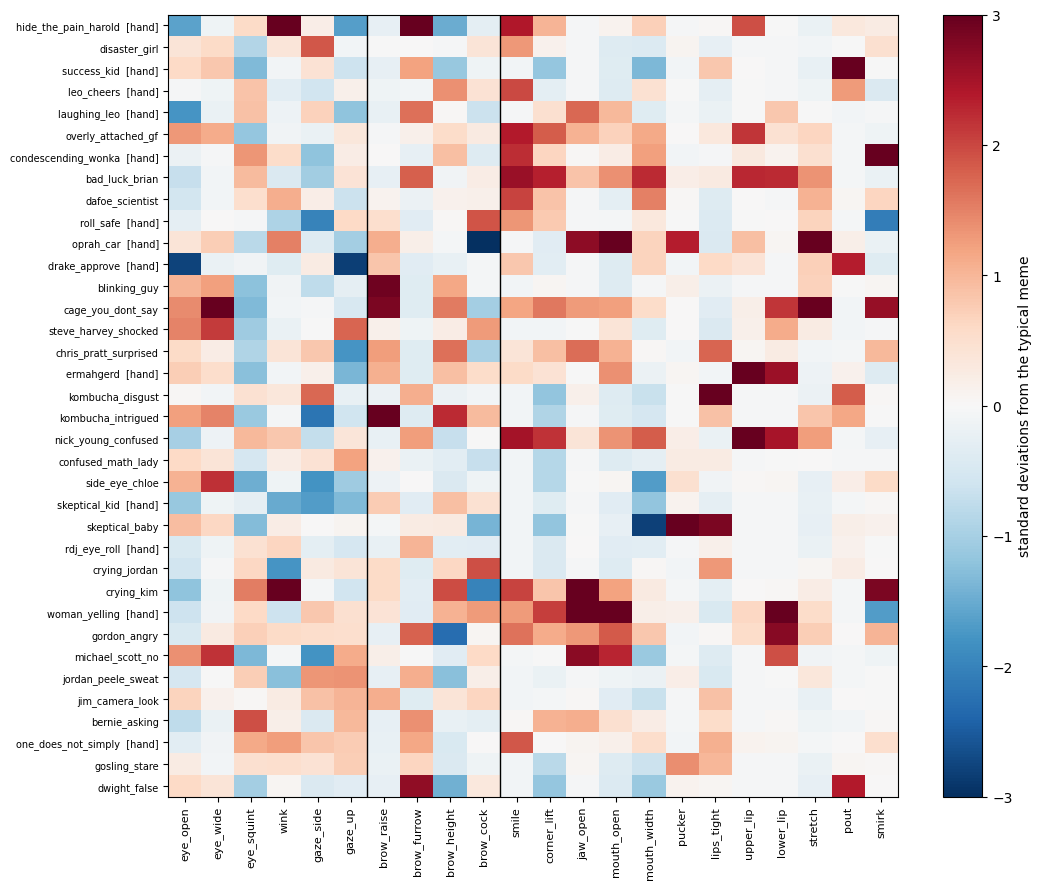

In [4]:
# What the matcher sees: every meme's embedding (eyes | brows | mouth). Red = more than a typical meme, blue = less.
plt.figure(figsize=(11, 9))
plt.imshow(M / W, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3)
plt.xticks(range(len(CH)), CH, rotation=90, fontsize=8)
plt.yticks(range(len(memes)), [i + ('  [hand]' if H else '') for i, H in zip(memes.id, MEME_HANDS)], fontsize=7)
for c in (5.5, 9.5): plt.axvline(c, color='k', lw=1)
plt.colorbar(label='standard deviations from the typical meme'); plt.tight_layout(); plt.show()

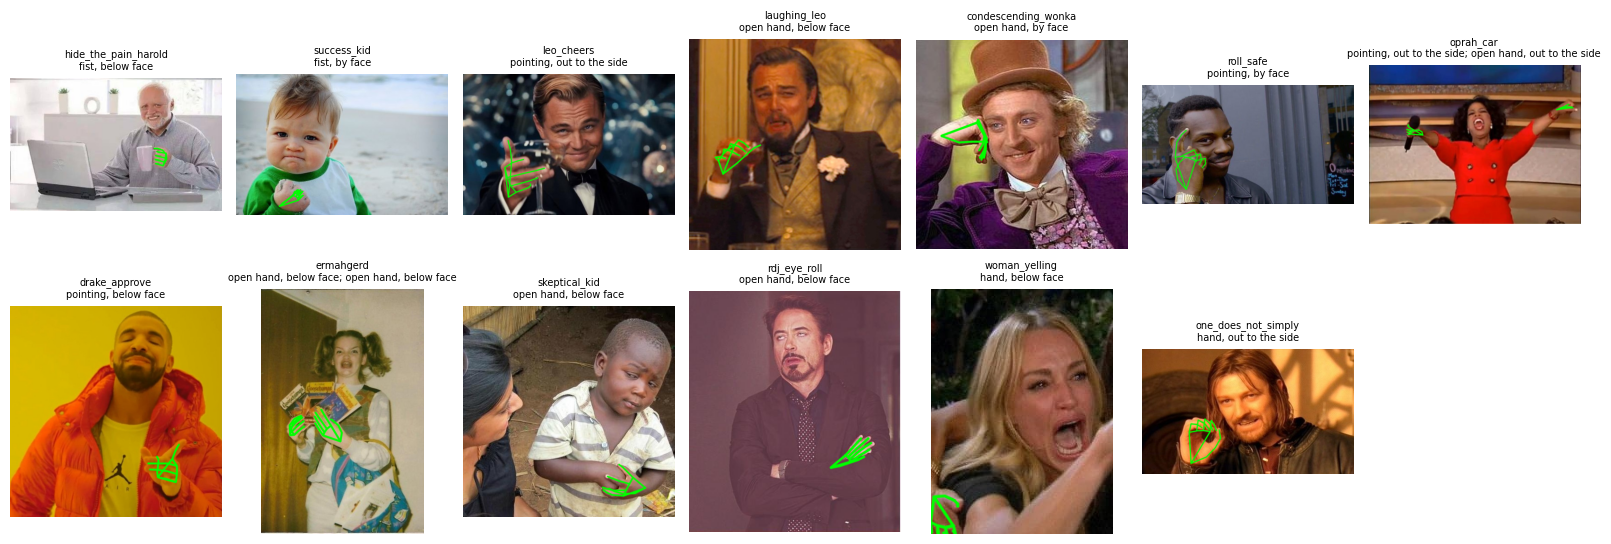

In [5]:
# The hands found in the memes (these are what your own hand is compared against)
BONES = [(0, 1, 2, 3, 4), (0, 5, 6, 7, 8), (9, 10, 11, 12), (13, 14, 15, 16), (0, 17, 18, 19, 20), (5, 9, 13, 17)]

def draw_hands(img, hands, color=(0, 255, 0)):
    for hd in hands:
        for bone in BONES:
            cv2.polylines(img, [hd['px'][list(bone)].astype(np.int32)], False, color, max(2, img.shape[0] // 160), cv2.LINE_AA)
    return img

with_hands = [j for j, H in enumerate(MEME_HANDS) if H]
fig, axes = plt.subplots(2, -(-len(with_hands) // 2), figsize=(16, 5.5))
for ax in axes.flat: ax.axis('off')
for ax, j in zip(axes.flat, with_hands):
    ax.imshow(cv2.cvtColor(draw_hands(memes.img[j].copy(), MEME_HANDS[j]), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{memes.id[j]}\n' + '; '.join(describe(h) for h in MEME_HANDS[j]), fontsize=7)
plt.tight_layout(); plt.show()

## 3. Live webcam matching
Opens a window: webcam on the left, best-matching meme on the right, top-3 scores, your strongest expression channels and any detected hand overlaid.

1. **Keep a relaxed, neutral face for the first second** while it says *calibrating* — everything after is measured relative to that. Press **`c`** to recalibrate at any time (do this if the matches feel stuck or off).
2. Pull faces, and bring a hand into view: point at your temple, rest your cheek on your hand, hold a fist by your chin, raise a "glass"…
3. Press **`q`** (with the window focused) to quit.

Tuning knobs (in the cell above): `HAND_W` — how much a matching hand is worth compared with the face (0 turns hands off); `NEUTRAL` — lower makes it react to subtler expressions, higher makes it stay on the deadpan memes longer; `W` — eye/brow vs mouth weighting.
The first run may trigger the macOS camera-permission prompt — allow it and re-run the cell.

In [ ]:
FONT = cv2.FONT_HERSHEY_SIMPLEX
CALIB_FRAMES, SMOOTH, HAND_HOLD = 25, 0.5, 6     # frames to calibrate over; smoothing; frames a lost hand is remembered

def text(img, s, y, scale=0.7, color=(255, 255, 255)):
    cv2.putText(img, s, (12, y), FONT, scale, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, s, (12, y), FONT, scale, color, 2, cv2.LINE_AA)

def render(frame, x, hands, status=None):
    """Draw the match overlay for embedding x (None = nothing to match yet) next to the frame."""
    h = frame.shape[0]
    panel = np.zeros((h, h, 3), np.uint8)
    draw_hands(frame, hands)
    if x is None:
        text(frame, status, 30, color=(0, 200, 255))
    else:
        s = match(x, hands); top = np.argsort(-s)[:3]
        m = memes.img[top[0]]; k = h / max(m.shape[:2])
        m = cv2.resize(m, (int(m.shape[1] * k), int(m.shape[0] * k)))
        y0, x0 = (h - m.shape[0]) // 2, (h - m.shape[1]) // 2
        panel[y0:y0 + m.shape[0], x0:x0 + m.shape[1]] = m
        for i, j in enumerate(top):
            text(frame, f'{memes.meme[j]}  {s[j]:.2f}', 30 + 28 * i, color=(0, 255, 0) if i == 0 else (255, 255, 255))
        z = x / W; strongest = np.argsort(-np.abs(z))[:4]
        text(frame, '  '.join(f'{CH[i]} {z[i]:+.1f}' for i in strongest if abs(z[i]) > 0.5) or 'neutral', h - 40, 0.5)
        text(frame, 'hand: ' + ('; '.join(describe(hd) for hd in hands) or 'none'), h - 14, 0.5)
    return np.hstack([frame, panel])

class Tracker:
    """Per-frame state: calibration of the resting face, smoothing, and remembering a hand through dropouts."""
    def __init__(self):
        self.face, self.hand_model = make_face(vision.RunningMode.VIDEO), make_hands(vision.RunningMode.VIDEO)
        self.recalibrate()
    def recalibrate(self):
        self.calib, self.rest, self.f, self.hands, self.lost = [], None, None, [], 0
    def step(self, frame):
        """One mirrored webcam frame -> (embedding or None, hands, status text)."""
        img, ts = to_mp(frame), time.monotonic_ns() // 1_000_000
        found = face_channels(self.face.detect_for_video(img, ts), frame.shape)
        hand_res = self.hand_model.detect_for_video(img, ts)
        if found is None:
            self.f = None
            return None, [], 'no face'
        ch, centre, size = found
        new = np.array([ch[c] for c in CH])
        self.f = new if self.f is None else SMOOTH * self.f + (1 - SMOOTH) * new        # smooth out flicker
        hands = find_hands(hand_res, frame.shape, centre, size)
        if hands: self.hands, self.lost = hands, 0
        elif self.lost < HAND_HOLD: self.lost += 1                                      # keep the last hand briefly
        else: self.hands = []
        if self.rest is None:
            self.calib.append(new)
            if len(self.calib) < CALIB_FRAMES:
                return None, self.hands, f'relax your face - calibrating {len(self.calib)}/{CALIB_FRAMES}'
            self.rest = np.median(self.calib, axis=0)
        return embed(self.f, self.rest)[0], self.hands, None
    def close(self):
        self.face.close(); self.hand_model.close()

cap, tracker = cv2.VideoCapture(0), Tracker()
try:
    while True:
        ok, frame = cap.read()
        if not ok: print('no camera frame'); break
        frame = cv2.flip(frame, 1)                                        # mirror view
        cv2.imshow('Meme Match - c: recalibrate, q: quit', render(frame, *tracker.step(frame)))
        key = cv2.waitKey(1) & 0xFF
        if key == ord('q'): break
        if key == ord('c'): tracker.recalibrate()
finally:
    cap.release(); tracker.close(); cv2.destroyAllWindows(); cv2.waitKey(1)